# National influenza activity: exploratory analysis

This notebook documents the shared ILI+ data and fixed threshold. ILI+ = weighted ILI percentage × influenza-positive fraction. It is a surveillance proxy, not population infection prevalence or a count of hospital patients.

The checked-in national series starts in 2016–17, although the requested training start is 2015–16. Raw observations are retained; no COVID imputation is performed here. The threshold is calculated from 57 raw observations in MMWR weeks 21–39 of 2023, 2024 and 2025, before the test period. Sample SD uses ddof=1.

Data source: `data/processed/ili_plus_weekly.csv`, produced by `src/fetch_ili_plus.py` from Delphi fluview and fluview_clinical. Definitions: `src/config.py`. The shared repository contains the components needed to verify the formula.

Run the cells below from the repository root or notebooks directory to reproduce the checks and plots. Embedded figures are saved snapshots; rerun after any data or configuration change.

In [ ]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src/config.py").exists():
    root = root.parent
assert (root / "src/config.py").exists(), "Open inside the project repository"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.eda import run
data, seasons, summary = run()
seasons

## Observed history

The full series is shown for context. Green marks test forecast origins; these observations are not used to choose or tune the threshold. The threshold is low relative to seasonal peaks, so the onset detail below uses a separate vertical scale.

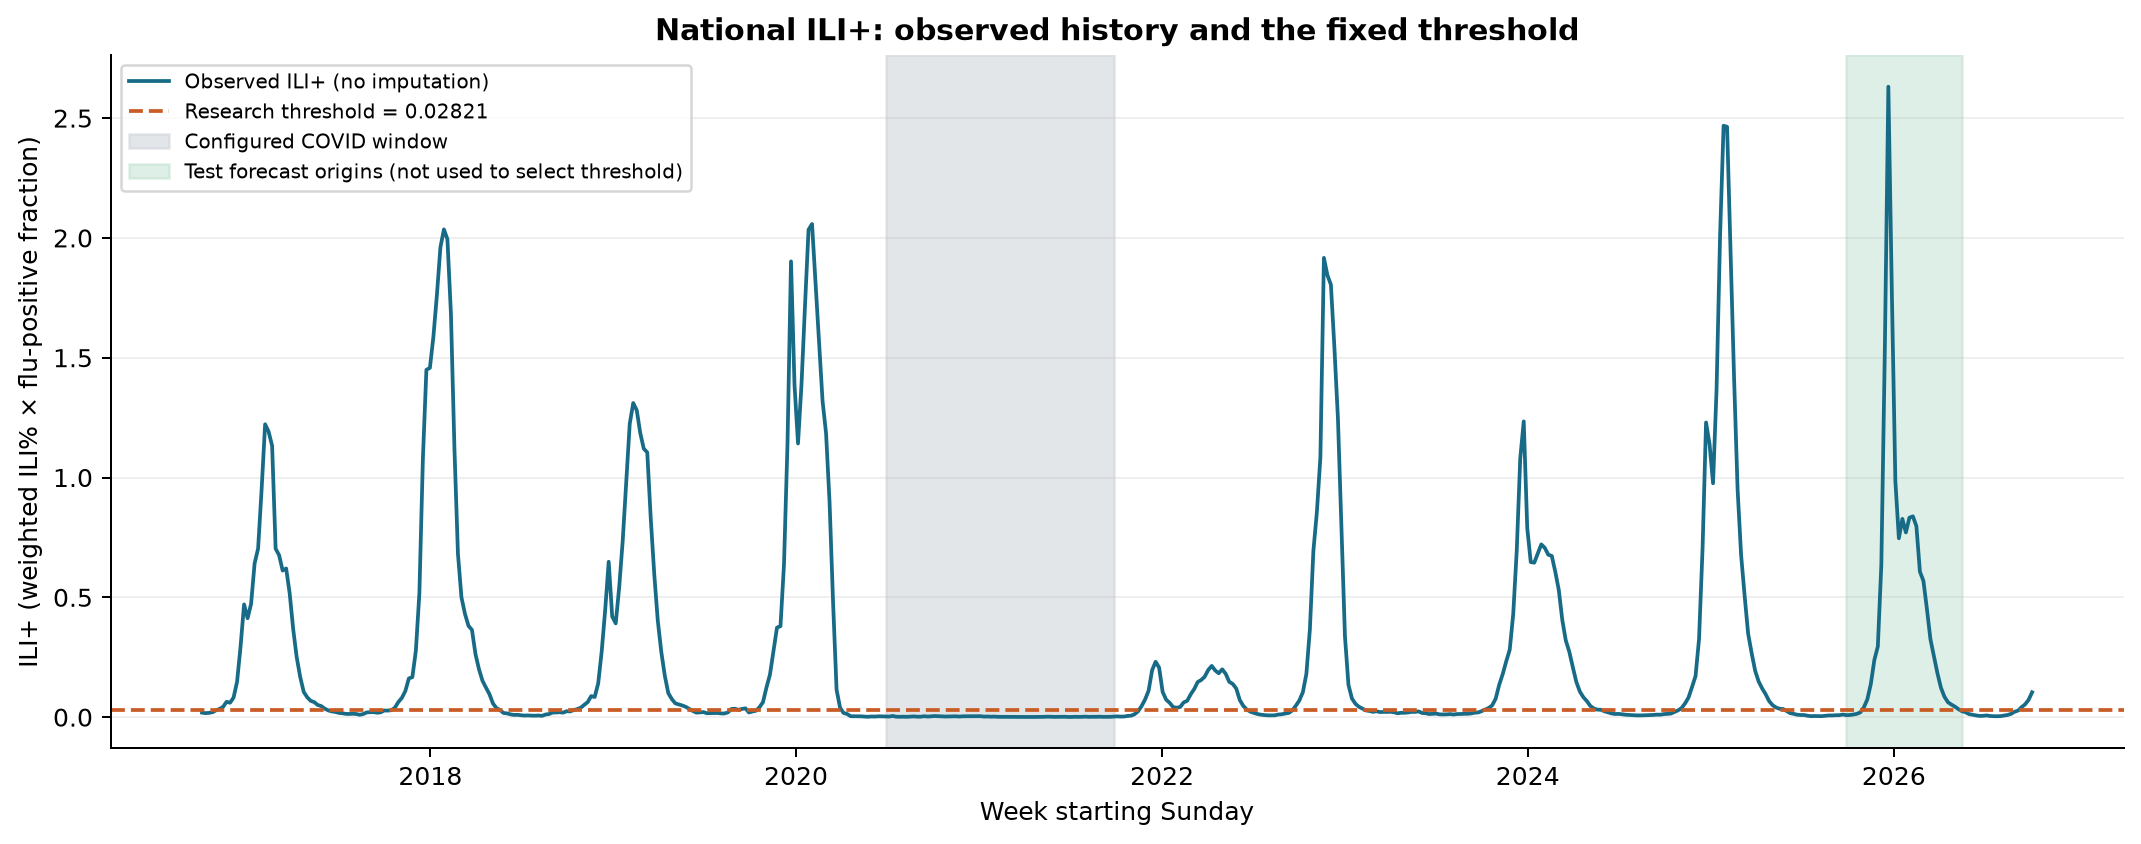

## Seasonal comparison

Only pre-test seasons are compared. Curves show the full surveillance year, aligned by elapsed weeks since week 40. The 2020–21 season remains observed, not imputed. Years containing a 53rd week have a one-week difference in calendar alignment.

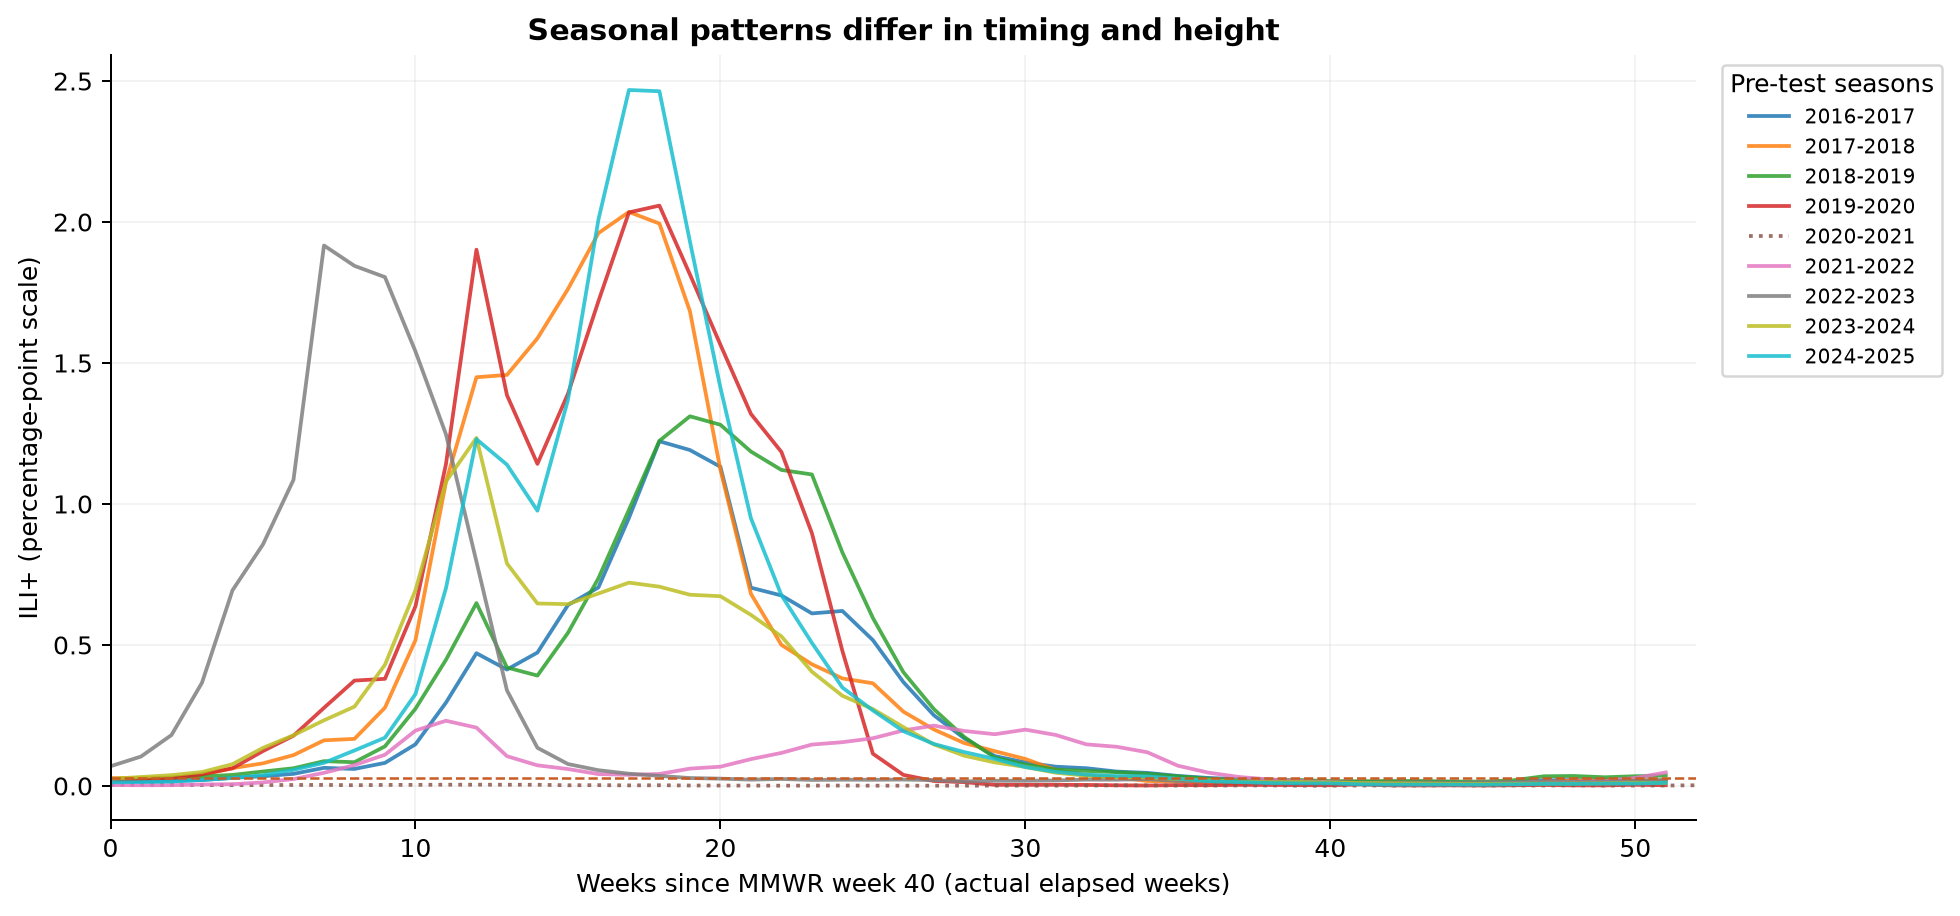

## Threshold and onset

The threshold identifies departure from low activity; it is not validated as a hospital surge trigger. Seven of nine pre-test seasons have an October onset under this rule, including 2022–23, which is already above threshold at the start of the analysis window. 2020–21 never exceeds it for two consecutive active-season weeks. An onset date is confirmed only after the second week. Historical application of this fixed threshold is descriptive, not a real-time backtest.

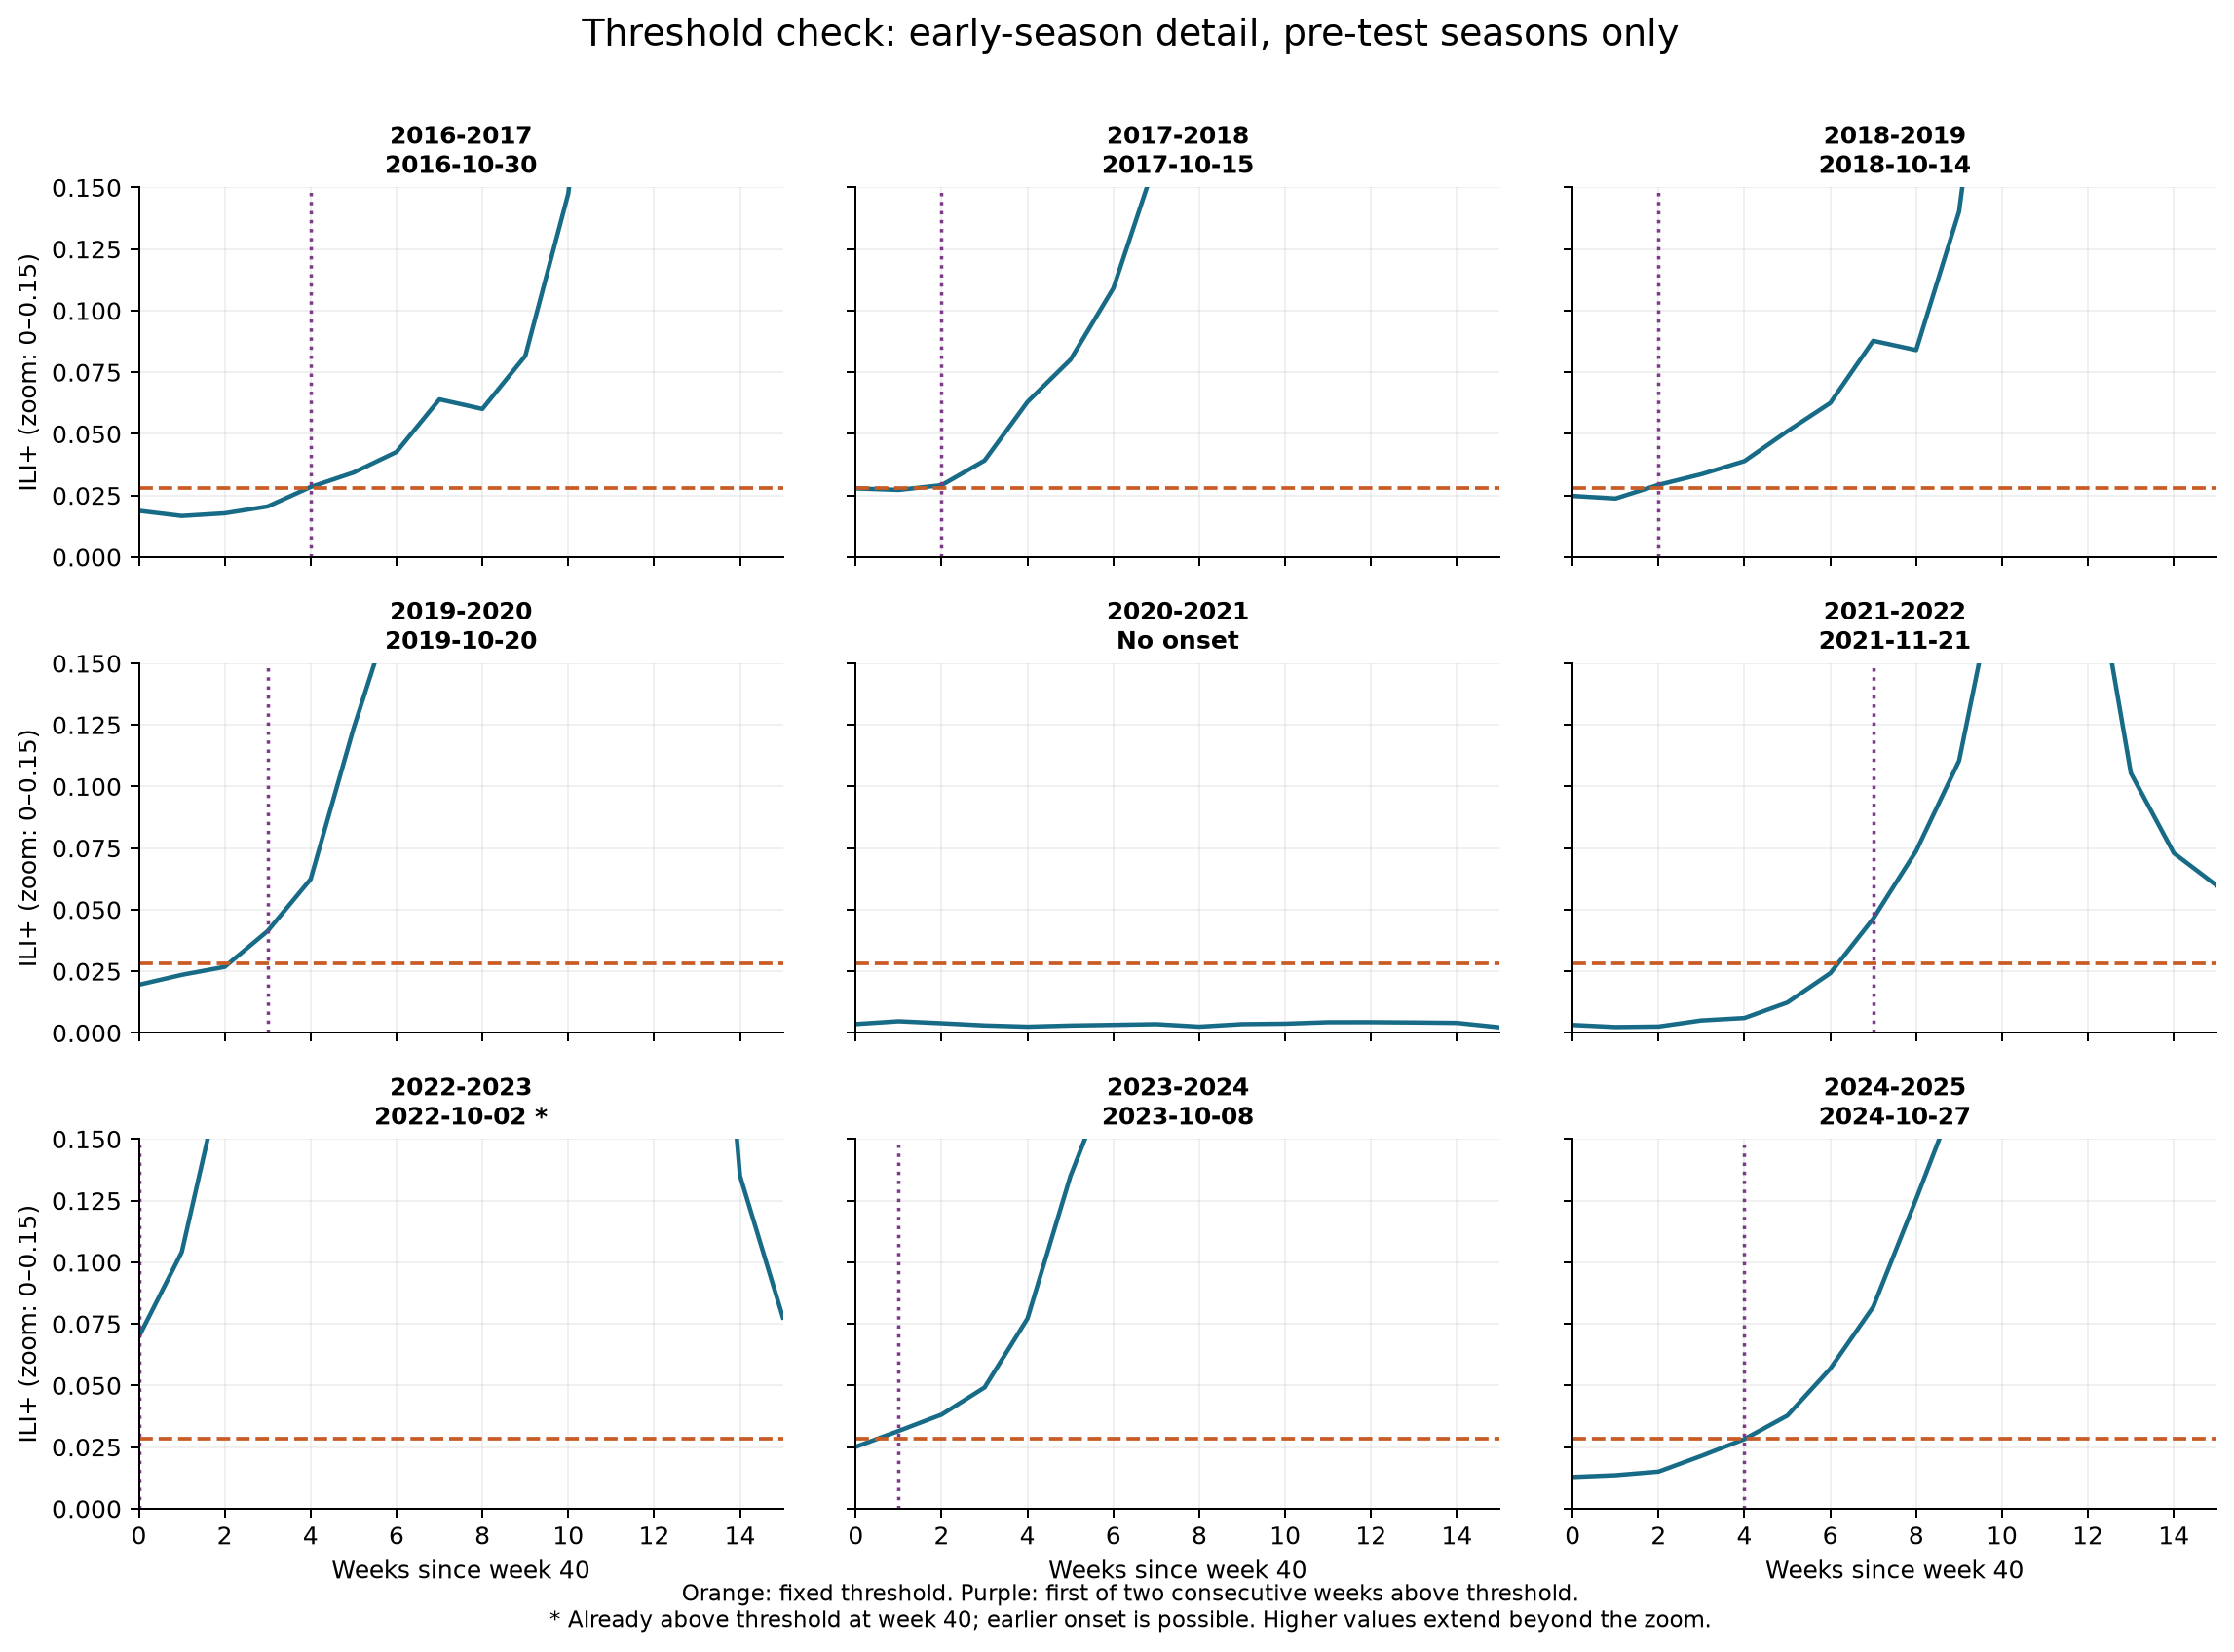

## Peak timing

Peaks here are maxima within MMWR weeks 40–20, as specified for active-season evaluation. They are not necessarily the maximum of the full surveillance year; late peaks outside that window are excluded. The COVID-season maximum should not be interpreted as a substantial outbreak.

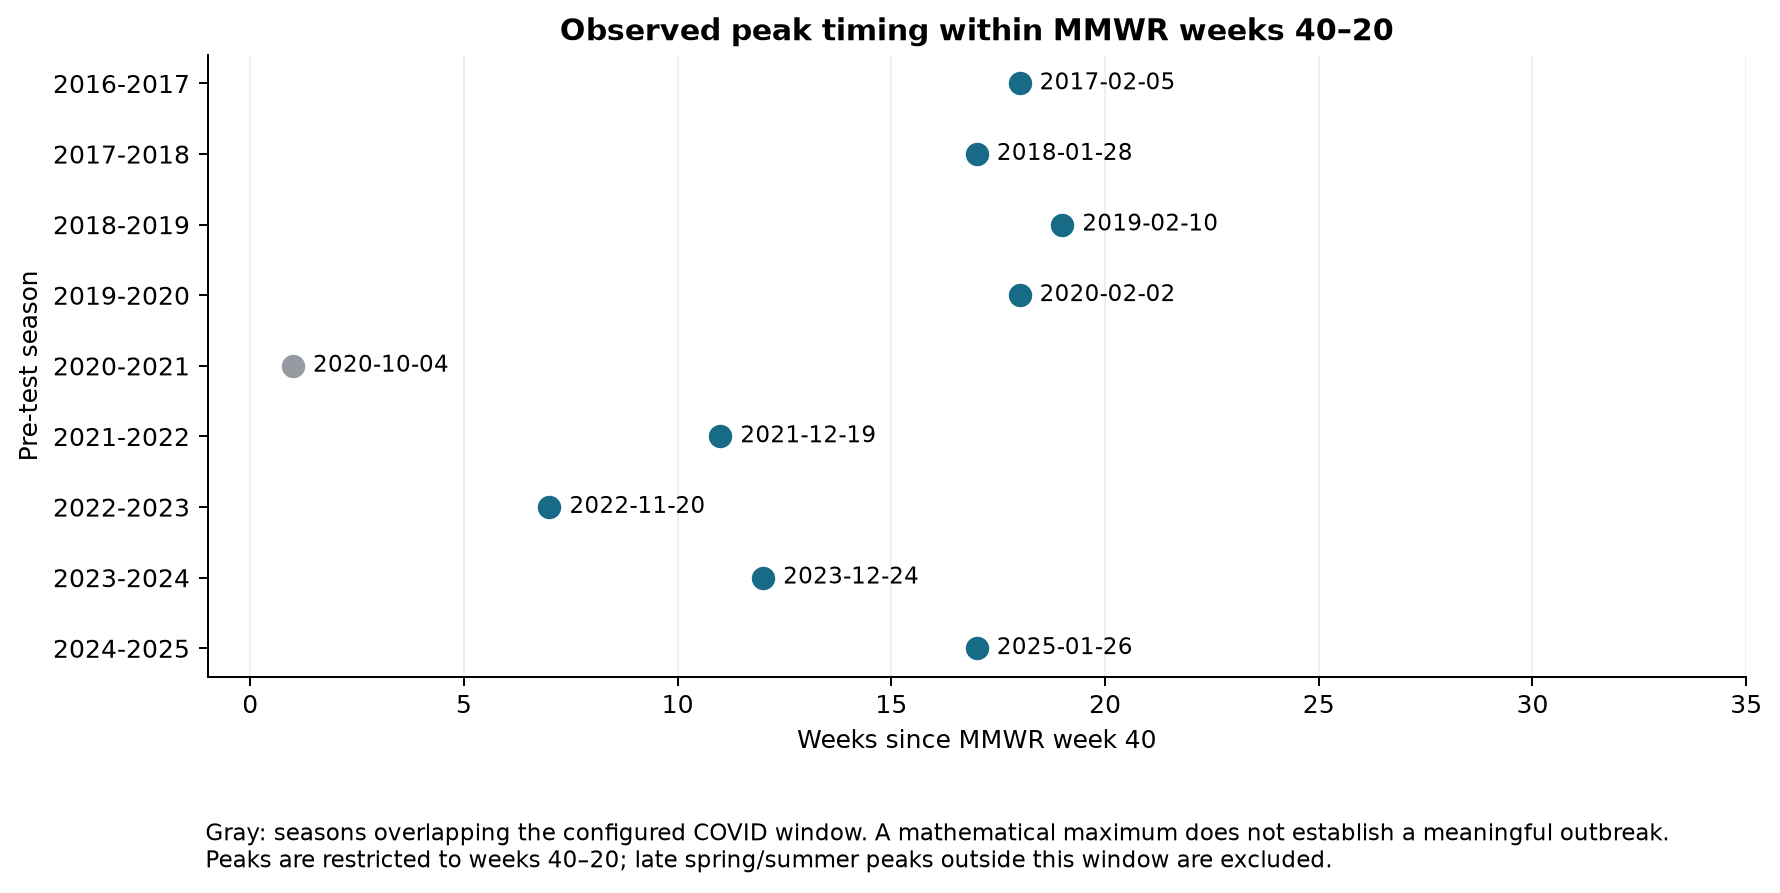

In [ ]:
from IPython.display import Image, display
for name in ["01_ili_plus_history.png", "02_seasonal_overlay.png", "03_threshold_onset_check.png", "04_peak_timing.png"]:
    display(Image(filename=str(root / "results/figures" / name)))
summary

## Interpretation and handoff

National weekly ILI+ combines weighted influenza-like-illness visits with clinical-laboratory influenza positivity. The checked-in data contain 523 consecutive weeks from October 2, 2016 through October 4, 2026, with no duplicate or missing national weeks. The shared research threshold is 0.0282121, calculated as the mean plus two sample standard deviations of the three pre-test offseasons. Historical patterns support interpreting it as a low-activity departure signal; they do not establish that crossing it warrants a specific staffing or bed-capacity action. The COVID disruption, retrospective data revisions, season-window limits, and early or left-censored onsets should be disclosed.

Keep the threshold unchanged during test evaluation. Agree on event handling when the origin is already above threshold, when onset starts at the horizon boundary, and when a seasonal peak cannot be identified from a four-week forecast alone. These are probability/evaluation definitions, not reasons to tune the threshold against test results.